In [1]:
%pip install matplotlib pillow

Note: you may need to restart the kernel to use updated packages.


In [6]:
from pathlib import Path

DATA_DIR = Path("../data/VOCdevkit")

VOC_DIR = DATA_DIR / "VOC2012"  

IMAGE_DIR = VOC_DIR / "JPEGImages"
ANNOTATION_DIR = VOC_DIR / "Annotations"

In [ ]:
import xml.etree.ElementTree as ET

image_id = "2007_000127"

xml_path = ANNOTATION_DIR / f"{image_id}.xml"
root = ET.parse(xml_path).getroot()

for obj in root.findall("object"):
    class_name = obj.findtext("name")
    bbox = obj.find("bndbox")

    xmin = int(bbox.findtext("xmin"))
    ymin = int(bbox.findtext("ymin"))
    xmax = int(bbox.findtext("xmax"))
    ymax = int(bbox.findtext("ymax"))

    print(class_name, (xmin, ymin, xmax, ymax))

FileNotFoundError: [Errno 2] No such file or directory: '..\\data\\VOCdevkit\\VOC2012\\Annotations\\2007_000127.xml'

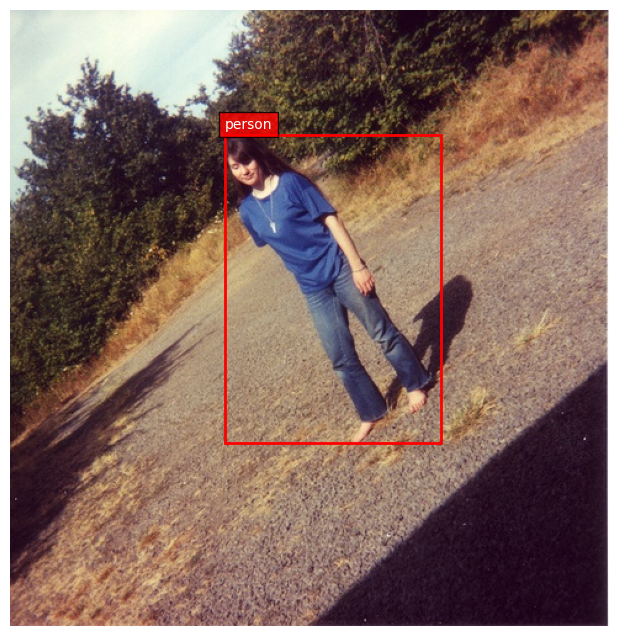

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from PIL import Image

image_path = IMAGE_DIR / f"{image_id}.jpg"
image = Image.open(image_path).convert("RGB")

fig, ax = plt.subplots(1, figsize=(12, 8))
ax.imshow(image)

for obj in root.findall("object"):
    class_name = obj.findtext("name")
    bbox = obj.find("bndbox")

    xmin = int(bbox.findtext("xmin"))
    ymin = int(bbox.findtext("ymin"))
    xmax = int(bbox.findtext("xmax"))
    ymax = int(bbox.findtext("ymax"))

    rect = patches.Rectangle(
        (xmin, ymin),
        xmax - xmin,
        ymax - ymin,
        linewidth=2,
        edgecolor="red",
        facecolor="none",
    )
    ax.add_patch(rect)

    ax.text(
        xmin,
        max(ymin - 5, 0),
        class_name,
        color="white",
        fontsize=10,
        bbox=dict(facecolor="red", alpha=0.8),
    )

ax.axis("off")
plt.show()